# Lab 03: ML/DL Techniques in Cybersecurity
## Part 2: Unsupervised Learning Algorithms for Threat and Anomaly Detection

**Course:** IA for Cybersecurity — 3rd Year / Second Cycle (Option: CyS)  
**Instructor:** Dr. R. BOUSMAHA  
**Deliverable:** Complete Research & Implementation Notebook

---

### Executive Summary & Objectives
In modern enterprise networks, signature-based Intrusion Detection Systems (IDS) frequently fail against novel zero-day exploits, evasive lateral movement, and advanced persistent threats (APTs). Unsupervised anomaly detection provides an alternative paradigm by profiling the baseline structure of normal network behavior and flagging deviations without relying on historical attack signatures.

**Core Principles & Guidelines:**
1. **Unsupervised Pipeline:** Model training is conducted **strictly on normal traffic**. Labels are completely withheld and utilized solely for post-hoc empirical evaluation.
2. **Dual-Domain Evaluation:** The pipeline is developed and benchmarked on a rigorously engineered **Synthetic NetFlow Dataset** (Part A & B) and subsequently validated on the real-world **CIC-IDS2017 Benchmark** (Part C) to examine model generalizability and distributional domain shift.
3. **Multi-Model Comparison:** Evaluating **Isolation Forest**, **Local Outlier Factor (LOF)**, **One-Class SVM (OC-SVM)**, and **Gaussian Mixture Models (GMM)** across precision, recall, F1-score, FPR, and ROC/PR curves.
4. **Hyperparameter Sensitivity:** Systematically tuning decision boundaries, local neighborhoods, and kernel bandwidths.

## 0. Environment Setup & Library Initialization
We initialize our scientific computing stack: `numpy` and `pandas` for vector operations and tabular data manipulation; `scipy`, `scikit-learn` for preprocessing, clustering, and anomaly detection; and `matplotlib` / `seaborn` for publication-quality visual diagnostics.

In [1]:
# Google Colab automatic environment detection and path resolution
import os
import sys

if 'google.colab' in sys.modules:
    print("Detected Google Colab environment.")
    if os.path.exists("colab_bundle.zip"):
        os.system("unzip -o -q colab_bundle.zip")
        print("Extracted colab_bundle.zip successfully.")
    elif os.path.exists("/content/colab_bundle.zip"):
        os.system("unzip -o -q /content/colab_bundle.zip -d /content/")
        print("Extracted /content/colab_bundle.zip successfully.")

import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# SciPy & Scikit-Learn tools
from scipy import stats
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

# Configuration & Styling
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f"Environment initialized successfully. Random Seed: {RANDOM_STATE}")

Environment initialized successfully. Random Seed: 42


---
# Part A — Synthetic Dataset Generation

### A.1 Mathematical & Cybersecurity Justification of Distributions
Simulating realistic network flows at the statistical NetFlow level requires selecting probability distributions that mirror physical networking processes:
1. **Lognormal Distribution for Flow Durations & Transfer Volumes:**
   Flow volumes and lifetimes in IP networks are well-known to follow heavy-tailed, multiplicative dynamics (Pareto or Lognormal):
   $$\ln(X) \sim \mathcal{N}(\mu, \sigma^2)$$
   This captures the reality that most flows are short-lived exchanges (HTTP handshakes, DNS queries), while a fraction of flows transfer megabytes or gigabytes over minutes.
2. **Exponential Distribution for Inter-Arrival Times:**
   In accordance with queuing theory and Poisson point processes, packet and connection inter-arrival times follow:
   $$f(t) = \lambda e^{-\lambda t}, \quad t \ge 0$$
   Normal interactive traffic exhibits burstiness followed by idle intervals, whereas automated floods (DDoS) exhibit near-zero variance and tiny inter-arrival scales.
3. **Poisson & Negative Binomial for Packet Counts:**
   Packet counts for discrete transactions (e.g., DNS queries, web page components) are modeled using Poisson or over-dispersed Negative Binomial distributions.

### A.2 Modeled Profiles & Anomaly Injection
We implement **five legitimate normal profiles** and **four distinct cyberattack scenarios**:
* **Normal Profiles:**
  1. *Web Browsing (HTTP/HTTPS):* Moderate durations, asymmetric payloads ($bytes_{dst} > bytes_{src}$), concurrent socket connections.
  2. *DNS Queries (UDP 53):* Sub-second durations ($<100$ ms), minimal symmetric bytes ($50-400$ B), 1-2 packets.
  3. *Legitimate SSH (TCP 22):* Prolonged interactive duration ($>60$ s), low byte throughput, keystroke bursts with high inter-arrival times.
  4. *Software Downloads & Updates (HTTP/HTTPS):* Large inbound volumes ($>1$ MB), sustained high throughput, high packet counts.
  5. *File Transfers & Backups (SMB/NFS/SFTP):* Symmetrical or heavy outbound volumes, MTU-optimized packets.
* **Attack Scenarios (with controlled overlap):**
  1. *Port Scanning:* Minimal bytes/packets, extremely high distinct target ports in window (`unique_ports_window`). Overlaps with multi-tab web browsers on lower scan speeds.
  2. *DDoS Flooding:* Extreme connection frequency (`conn_count_window`), microsecond inter-arrival times, small uniform packet sizes.
  3. *Data Exfiltration:* Massive outbound volume (`src_bytes` dominant), skewed directionality. Directly overlaps in volume with legitimate *File Backups*, forcing models to learn multi-dimensional contextual features.
  4. *Brute Force (Credential Stuffing):* Rapid repeated connection attempts to a fixed authentication port (22, 21, 3389). Individual flows resemble normal logins, but window frequency is elevated.

In [2]:
from synthetic_generator import generate_synthetic_netflow

# Generate 60,000 flows with 6% anomaly contamination
SYNTH_FLOWS = 60000
ANOMALY_RATE = 0.06

print(f"Generating synthetic NetFlow dataset ({SYNTH_FLOWS:,} flows, anomaly rate: {ANOMALY_RATE:.1%})...")
df_synth = generate_synthetic_netflow(n_flows=SYNTH_FLOWS, anomaly_rate=ANOMALY_RATE, random_state=RANDOM_STATE)

# Export to CSV as required by task A.3
df_synth.to_csv("synthetic_traffic.csv", index=False)
print(f"Dataset successfully created and exported to 'synthetic_traffic.csv'. Shape: {df_synth.shape}")

# Preview dataset
display(df_synth.head())

Generating synthetic NetFlow dataset (60,000 flows, anomaly rate: 6.0%)...


Dataset successfully created and exported to 'synthetic_traffic.csv'. Shape: (60000, 18)


,duration,protocol,dst_port,src_bytes,dst_bytes,src_packets,dst_packets,conn_count_window,unique_ports_window,inter_arrival_time,traffic_type,label,total_bytes,total_packets,bytes_per_second,packets_per_second,bytes_per_packet,byte_ratio
0,1.880306,6,443,697.644801,10771.309950,15,22,22,1,0.023333,web_browsing,0,11468.954751,37,6099.192040,19.676606,309.971750,0.064856
1,54.472589,6,22,5200.970553,3000.000000,52,49,2,1,27.275958,ssh_session,0,8200.970553,101,150.551968,1.854140,81.197728,1.733412
2,39.039353,6,22,3885.099286,13961.998244,28,513,2,1,9.300136,ssh_session,0,17847.097530,541,457.155418,13.857776,32.989090,0.278314
3,1.067713,6,443,1030.974866,26710.218899,12,26,7,1,0.223570,web_browsing,0,27741.193766,38,25979.447084,35.586752,730.031415,0.038635
4,1.315524,6,443,657.732212,20119.658387,10,41,10,1,2.549325,web_browsing,0,20777.390598,51,15792.808027,38.764888,407.399816,0.032739


In [3]:
# Detailed profile and label breakdown
print("=== Synthetic Dataset Composition ===")
print(f"Total Flows: {len(df_synth):,}")
print("\nBinary Class Distribution:")
print(df_synth['label'].value_counts(normalize=True).apply(lambda x: f"{x*100:.2f}%"))
print("\nProfile Subcategory Breakdown:")
display(df_synth['traffic_type'].value_counts().to_frame("Flow Count"))

=== Synthetic Dataset Composition ===
Total Flows: 60,000

Binary Class Distribution:
label
0    94.00%
1     6.00%
Name: proportion, dtype: object

Profile Subcategory Breakdown:


,Flow Count
traffic_type,
web_browsing,22560
dns_query,14100
software_update,8460
file_backup,5640
ssh_session,5640
ddos_flood,900
data_exfiltration,900
brute_force,900
port_scan,900


### A.3 Distribution Visualization & Controlled Overlap Verification
To confirm that our dataset avoids an "artificially perfect separation", we inspect the distributions of key features across normal and attack categories. Notice the overlapping tails in flow duration, outbound bytes, and connection rates.

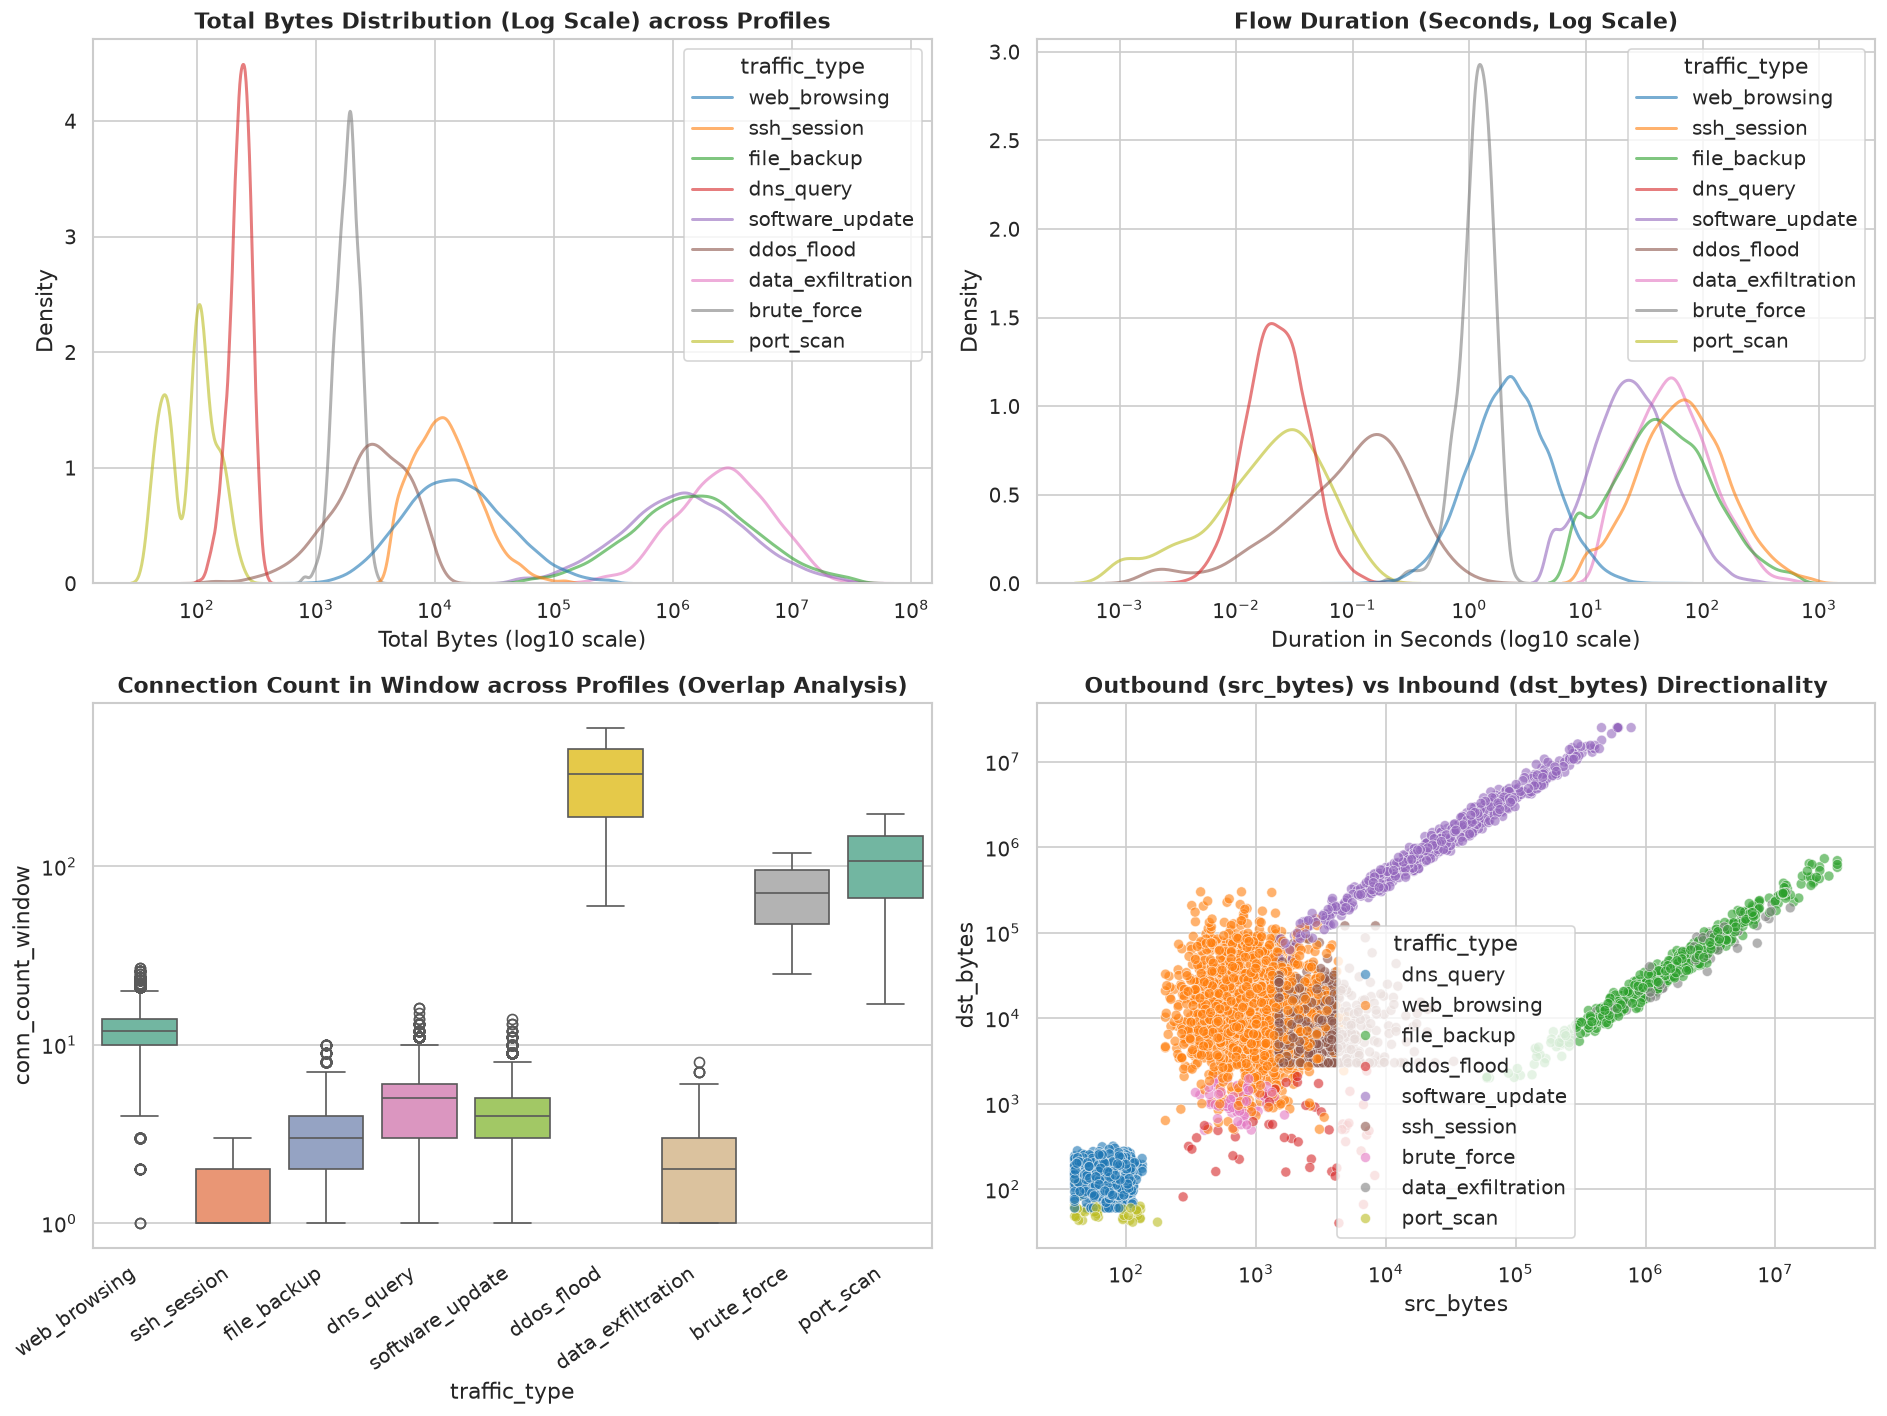

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Total Bytes Distribution (Log Scale)
sns.kdeplot(
    data=df_synth, x='total_bytes', hue='traffic_type', log_scale=True,
    common_norm=False, palette='tab10', ax=axes[0, 0], alpha=0.6, linewidth=1.8
)
axes[0, 0].set_title("Total Bytes Distribution (Log Scale) across Profiles", fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel("Total Bytes (log10 scale)")

# 2. Connection Duration (Log Scale)
sns.kdeplot(
    data=df_synth, x='duration', hue='traffic_type', log_scale=True,
    common_norm=False, palette='tab10', ax=axes[0, 1], alpha=0.6, linewidth=1.8
)
axes[0, 1].set_title("Flow Duration (Seconds, Log Scale)", fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel("Duration in Seconds (log10 scale)")

# 3. Connections in Window: Normal vs Attacks (Overlap Demonstration)
sns.boxplot(
    data=df_synth, x='traffic_type', y='conn_count_window',
    ax=axes[1, 0], palette='Set2'
)
axes[1, 0].set_title("Connection Count in Window across Profiles (Overlap Analysis)", fontsize=13, fontweight='bold')
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=35, ha='right')
axes[1, 0].set_yscale('log')

# 4. Outbound vs Inbound Bytes (Exfiltration vs Backup Overlap)
sns.scatterplot(
    data=df_synth.sample(n=5000, random_state=RANDOM_STATE),
    x='src_bytes', y='dst_bytes', hue='traffic_type',
    alpha=0.6, palette='tab10', ax=axes[1, 1]
)
axes[1, 1].set_xscale('log')
axes[1, 1].set_yscale('log')
axes[1, 1].set_title("Outbound (src_bytes) vs Inbound (dst_bytes) Directionality", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

---
# Part B — Preprocessing, Clustering and Anomaly Detection

### B.1 Preprocessing, Feature Engineering & Unsupervised Train/Test Split
Strict adherence to unsupervised methodology requires:
1. **Cleaning:** Verification of missing values (`NaN`), duplicates, and infinite values.
2. **Feature Selection:** Selecting quantitative behavioral attributes that capture flow dynamics, volume, rate, and topology:
   - `duration`, `src_bytes`, `dst_bytes`, `src_packets`, `dst_packets`
   - `conn_count_window`, `unique_ports_window`, `inter_arrival_time`
   - `bytes_per_second`, `packets_per_second`, `bytes_per_packet`, `byte_ratio`
3. **Logarithmic Transformation:** Heavy-tailed features are stabilized using $x' = \ln(1 + x)$ to compress exponential variance into quasi-normal scales.
4. **Leak-Free Scaling:** `RobustScaler` (based on median and interquartile range) is fitted **strictly on normal training flows** and used to transform the test set without refitting:
   $$z = \frac{x - \text{median}(X_{train})}{\text{IQR}(X_{train})}$$
5. **Data Split:**
   - **Training Set:** 80% of normal traffic only ($y=0$). Zero attack samples.
   - **Test Set:** Remaining 20% of normal traffic + 100% of injected anomalies ($y=1$).

In [5]:
# Feature selection
FEATURE_COLS = [
    'duration', 'src_bytes', 'dst_bytes', 'src_packets', 'dst_packets',
    'conn_count_window', 'unique_ports_window', 'inter_arrival_time',
    'bytes_per_second', 'packets_per_second', 'bytes_per_packet', 'byte_ratio'
]

# 1. Quality Check
print("Missing values per feature:")
print(df_synth[FEATURE_COLS].isnull().sum())
print(f"Duplicate rows detected: {df_synth[FEATURE_COLS].duplicated().sum()}")

# 2. Strict Unsupervised Partitioning
normal_subset = df_synth[df_synth['label'] == 0].copy()
anomaly_subset = df_synth[df_synth['label'] == 1].copy()

# Split normal traffic into 80% train / 20% test
train_normal, test_normal = train_test_split(normal_subset, test_size=0.20, random_state=RANDOM_STATE)

# Construct Test Set: 20% Normal + All Anomalies
test_combined = pd.concat([test_normal, anomaly_subset], axis=0).sample(frac=1.0, random_state=RANDOM_STATE).reset_index(drop=True)

# 3. Log-transform heavy-tailed features
X_train_raw = np.log1p(train_normal[FEATURE_COLS].values)
X_test_raw = np.log1p(test_combined[FEATURE_COLS].values)

y_test_synth = test_combined['label'].values
y_test_types_synth = test_combined['traffic_type'].values

# 4. Fit scaler strictly on training normal data
scaler_synth = RobustScaler()
X_train_synth = scaler_synth.fit_transform(X_train_raw)
X_test_synth = scaler_synth.transform(X_test_raw)

print(f"\nTraining Set (Normal Only): {X_train_synth.shape[0]:,} flows across {X_train_synth.shape[1]} features.")
print(f"Test Set (Normal + Attack): {X_test_synth.shape[0]:,} flows (Normal: {len(test_normal):,}, Anomalies: {len(anomaly_subset):,}).")
print(f"Test Anomaly Ground Truth Proportion: {y_test_synth.mean():.2%}")

Missing values per feature:
duration               0
src_bytes              0
dst_bytes              0
src_packets            0
dst_packets            0
conn_count_window      0
unique_ports_window    0
inter_arrival_time     0
bytes_per_second       0
packets_per_second     0
bytes_per_packet       0
byte_ratio             0
dtype: int64
Duplicate rows detected: 0

Training Set (Normal Only): 45,120 flows across 12 features.
Test Set (Normal + Attack): 14,880 flows (Normal: 11,280, Anomalies: 3,600).
Test Anomaly Ground Truth Proportion: 24.19%


### B.2 Profiling Normal Traffic with Clustering
Before running anomaly detectors, an enterprise cybersecurity team must understand the behavioral modes of normal network activity. We apply **K-Means clustering** ($k=4$) to partition normal training flows and project them onto a **2D Principal Component Analysis (PCA)** space.

**Behavioral Cluster Interpretations:**
* **Cluster 0 — Micro-Transactions & DNS:** Minimal bytes, microsecond duration, single packet exchanges.
* **Cluster 1 — Standard Interactive Web Browsing:** Moderate HTTP/HTTPS sessions, asymmetric inbound bytes.
* **Cluster 2 — Sustained Interactive Sessions (SSH):** Long duration, low packet throughput, keystroke patterns.
* **Cluster 3 — High-Throughput Bulk Transfers & Backups:** High packet counts, megabytes of data, high byte-per-packet ratios.

PCA Explained Variance: PC1 = 64.94%, PC2 = 15.68% (Total = 80.61%)


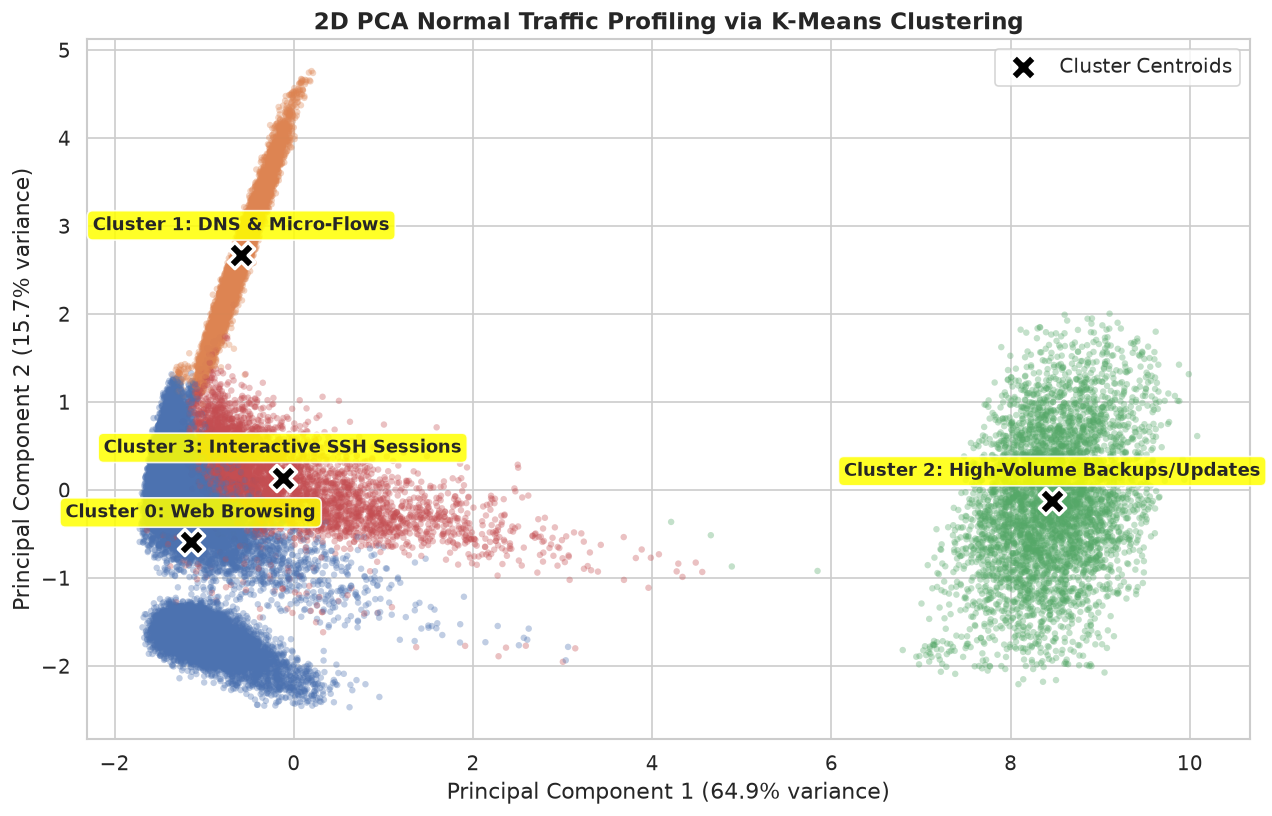

In [6]:
# Fit K-Means on normal training traffic
k_clusters = 4
kmeans = KMeans(n_clusters=k_clusters, random_state=RANDOM_STATE, n_init=10)
normal_clusters = kmeans.fit_predict(X_train_synth)

# 2D PCA Projection
pca_profiler = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca_profiler.fit_transform(X_train_synth)

var_exp = pca_profiler.explained_variance_ratio_
print(f"PCA Explained Variance: PC1 = {var_exp[0]:.2%}, PC2 = {var_exp[1]:.2%} (Total = {sum(var_exp):.2%})")

# Visualization
plt.figure(figsize=(11, 7))
palette = sns.color_palette("deep", k_clusters)
scatter = plt.scatter(
    X_train_pca[:, 0], X_train_pca[:, 1],
    c=[palette[c] for c in normal_clusters], alpha=0.35, s=15, edgecolors='none'
)

# Plot cluster centroids
centroids_pca = pca_profiler.transform(kmeans.cluster_centers_)
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    s=250, c='black', marker='X', edgecolors='white', linewidth=2, label='Cluster Centroids'
)

# Cluster annotations
cluster_labels = {
    0: "Cluster 0: Web Browsing",
    1: "Cluster 1: DNS & Micro-Flows",
    2: "Cluster 2: High-Volume Backups/Updates",
    3: "Cluster 3: Interactive SSH Sessions"
}

for idx, pt in enumerate(centroids_pca):
    plt.annotate(
        cluster_labels.get(idx, f"Cluster {idx}"),
        (pt[0], pt[1]),
        textcoords="offset points", xytext=(0, 15), ha='center',
        fontsize=11, fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.85)
    )

plt.title("2D PCA Normal Traffic Profiling via K-Means Clustering", fontsize=14, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({var_exp[0]:.1%} variance)")
plt.ylabel(f"Principal Component 2 ({var_exp[1]:.1%} variance)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### B.3 Anomaly Detection Algorithms: Principles & Model Implementation
We train **four distinct unsupervised algorithms** on normal traffic.

#### 1. Isolation Forest (`iForest`)
* **Principle:** Anomalies are "few and different", making them geometrically isolated early in random axis-aligned hierarchical partitions. It constructs an ensemble of Isolation Trees ($iTrees$). The anomaly score $s(x, n)$ depends on the average path length $h(x)$:
  $$s(x, n) = 2^{-\frac{\mathbb{E}(h(x))}{c(n)}}$$
  where $c(n) = 2(\ln(n - 1) + 0.5772) - \frac{2(n-1)}{n}$ is the average path length of unsuccessful searches in a Binary Search Tree.
* **Key Hyperparameters:** `n_estimators=100`, `contamination=0.08`, `max_samples='auto'`.

#### 2. Local Outlier Factor (`LOF`)
* **Principle:** Measures the local density deviation of a sample relative to its $k$-nearest neighbors. Anomalies reside in substantially sparser local neighborhoods. In novelty detection mode (`novelty=True`), the model establishes a reference neighbor structure strictly from normal training samples.
  $$\text{LOF}_k(p) = \frac{\sum_{o \in N_k(p)} \frac{\text{lrd}(o)}{\text{lrd}(p)}}{|N_k(p)|}$$
* **Key Hyperparameters:** `n_neighbors=25`, `novelty=True`, `contamination=0.08`.

#### 3. One-Class Support Vector Machine (`OC-SVM`)
* **Principle:** Maps normal data into a reproducing kernel Hilbert space (RKHS) via an RBF kernel and computes the maximum-margin hyperplane separating normal points from the coordinate origin:
  $$\min_{w, \xi, \rho} \frac{1}{2} \|w\|^2 + \frac{1}{\nu N} \sum_{i=1}^N \xi_i - \rho \quad \text{s.t.} \quad \langle w, \Phi(x_i) \rangle \ge \rho - \xi_i, \quad \xi_i \ge 0$$
* **Key Hyperparameters:** `kernel='rbf'`, `nu=0.08` (upper bound on outlier fraction), `gamma='scale'`.

#### 4. Gaussian Mixture Model (`GMM`)
* **Principle:** Semi-parametric density estimation assuming normal traffic is generated by a superposition of $K$ multivariate Gaussian components:
  $$p(x) = \sum_{k=1}^K \pi_k \mathcal{N}(x; \mu_k, \Sigma_k)$$
  Samples with low log-likelihood (below an empirical percentile threshold) are classified as anomalous.
* **Key Hyperparameters:** `n_components=4`, `covariance_type='full'`, `threshold_quantile=8%`.

In [7]:
models = {}
predictions = {}
decision_scores = {}
fit_times = {}

# Set uniform baseline expected contamination
CONTAMINATION = 0.08

# 1. Isolation Forest
print("Training Isolation Forest...")
t0 = time.time()
iforest = IsolationForest(
    n_estimators=100, contamination=CONTAMINATION,
    random_state=RANDOM_STATE, n_jobs=-1
)
iforest.fit(X_train_synth)
fit_times['Isolation Forest'] = time.time() - t0
# Note: iForest predict returns -1 for anomaly, +1 for normal
predictions['Isolation Forest'] = np.where(iforest.predict(X_test_synth) == -1, 1, 0)
# Score: lower means more anomalous -> invert for standard ROC/PR ranking
decision_scores['Isolation Forest'] = -iforest.score_samples(X_test_synth)
models['Isolation Forest'] = iforest

# 2. Local Outlier Factor (Novelty Mode)
print("Training Local Outlier Factor (Novelty Mode)...")
t0 = time.time()
# Subsample 15k training points for efficient neighbor indexing
sub_idx_lof = np.random.choice(len(X_train_synth), 15000, replace=False)
lof = LocalOutlierFactor(
    n_neighbors=25, novelty=True, contamination=CONTAMINATION, n_jobs=-1
)
lof.fit(X_train_synth[sub_idx_lof])
fit_times['LOF'] = time.time() - t0
predictions['LOF'] = np.where(lof.predict(X_test_synth) == -1, 1, 0)
decision_scores['LOF'] = -lof.decision_function(X_test_synth)
models['LOF'] = lof

# 3. One-Class SVM
print("Training One-Class SVM...")
t0 = time.time()
sub_idx_svm = np.random.choice(len(X_train_synth), 10000, replace=False)
ocsvm = OneClassSVM(kernel='rbf', nu=CONTAMINATION, gamma='scale')
ocsvm.fit(X_train_synth[sub_idx_svm])
fit_times['One-Class SVM'] = time.time() - t0
predictions['One-Class SVM'] = np.where(ocsvm.predict(X_test_synth) == -1, 1, 0)
decision_scores['One-Class SVM'] = -ocsvm.decision_function(X_test_synth)
models['One-Class SVM'] = ocsvm

# 4. Gaussian Mixture Model (GMM)
print("Training Gaussian Mixture Model...")
t0 = time.time()
gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=RANDOM_STATE)
gmm.fit(X_train_synth)
fit_times['GMM'] = time.time() - t0
# Score samples returns log-likelihood
train_log_dens = gmm.score_samples(X_train_synth)
gmm_thresh = np.percentile(train_log_dens, CONTAMINATION * 100)
test_log_dens = gmm.score_samples(X_test_synth)
predictions['GMM'] = np.where(test_log_dens < gmm_thresh, 1, 0)
decision_scores['GMM'] = -test_log_dens
models['GMM'] = gmm

print("\nAll models trained successfully!")
for name, t in fit_times.items():
    print(f"  {name:18s}: {t:.2f}s")

Training Isolation Forest...


Training Local Outlier Factor (Novelty Mode)...


Training One-Class SVM...


Training Gaussian Mixture Model...



All models trained successfully!
  Isolation Forest  : 0.41s
  LOF               : 0.21s
  One-Class SVM     : 0.30s
  GMM               : 3.08s


### B.4 Comprehensive Evaluation on Synthetic Test Set
We evaluate all algorithms on the test set containing **11,280 legitimate flows** and **3,600 attack flows** ($24.2\%$ anomaly prevalence in the test set).

**Evaluation Metrics:**
* **Precision:** $\frac{TP}{TP + FP}$ — Ability to avoid false alarms.
* **Recall (Detection Rate):** $\frac{TP}{TP + FN}$ — Ability to catch true cyber threats.
* **F1-Score:** Harmonic mean of precision and recall.
* **False Positive Rate (FPR):** $\frac{FP}{FP + TN}$ — Proportion of normal traffic incorrectly flagged as attacks.
* **ROC-AUC & PR-AUC:** Area under Receiver Operating Characteristic and Precision-Recall curves.

In [8]:
def evaluate_pipeline(y_true, preds_dict, scores_dict):
    results = []
    for model_name in preds_dict.keys():
        y_pred = preds_dict[model_name]
        scores = scores_dict[model_name]
        
        cm = confusion_matrix(y_true, y_pred)
        tn, fp, fn, tp = cm.ravel()
        
        prec = precision_score(y_true, y_pred)
        rec = recall_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred)
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
        roc = roc_auc_score(y_true, scores)
        pr_auc = average_precision_score(y_true, scores)
        
        results.append({
            'Algorithm': model_name,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1,
            'FPR': fpr,
            'ROC-AUC': roc,
            'PR-AUC': pr_auc,
            'TP': tp,
            'FP': fp,
            'TN': tn,
            'FN': fn
        })
    return pd.DataFrame(results)

df_synth_eval = evaluate_pipeline(y_test_synth, predictions, decision_scores)
print("=== Synthetic Dataset Anomaly Detection Benchmark ===")
display(df_synth_eval.set_index('Algorithm').style.format({
    'Precision': '{:.3f}', 'Recall': '{:.3f}', 'F1-Score': '{:.3f}',
    'FPR': '{:.3%}', 'ROC-AUC': '{:.3f}', 'PR-AUC': '{:.3f}',
    'TP': '{:,}', 'FP': '{:,}', 'TN': '{:,}', 'FN': '{:,}'
}))

=== Synthetic Dataset Anomaly Detection Benchmark ===


,Precision,Recall,F1-Score,FPR,ROC-AUC,PR-AUC,TP,FP,TN,FN
Algorithm,,,,,,,,,,
Isolation Forest,0.712,0.606,0.655,7.828%,0.901,0.774,"2,183",883,"10,397","1,417"
LOF,0.734,0.795,0.763,9.193%,0.888,0.870,"2,861","1,037","10,243",739
One-Class SVM,0.768,0.815,0.791,7.872%,0.925,0.887,"2,934",888,"10,392",666
GMM,0.743,0.706,0.724,7.810%,0.775,0.771,"2,543",881,"10,399","1,057"


### B.4.1 ROC Curves, PR Curves, and Confusion Matrices
We visualize the trade-offs between True Positive Rate and False Positive Rate across all decision thresholds.

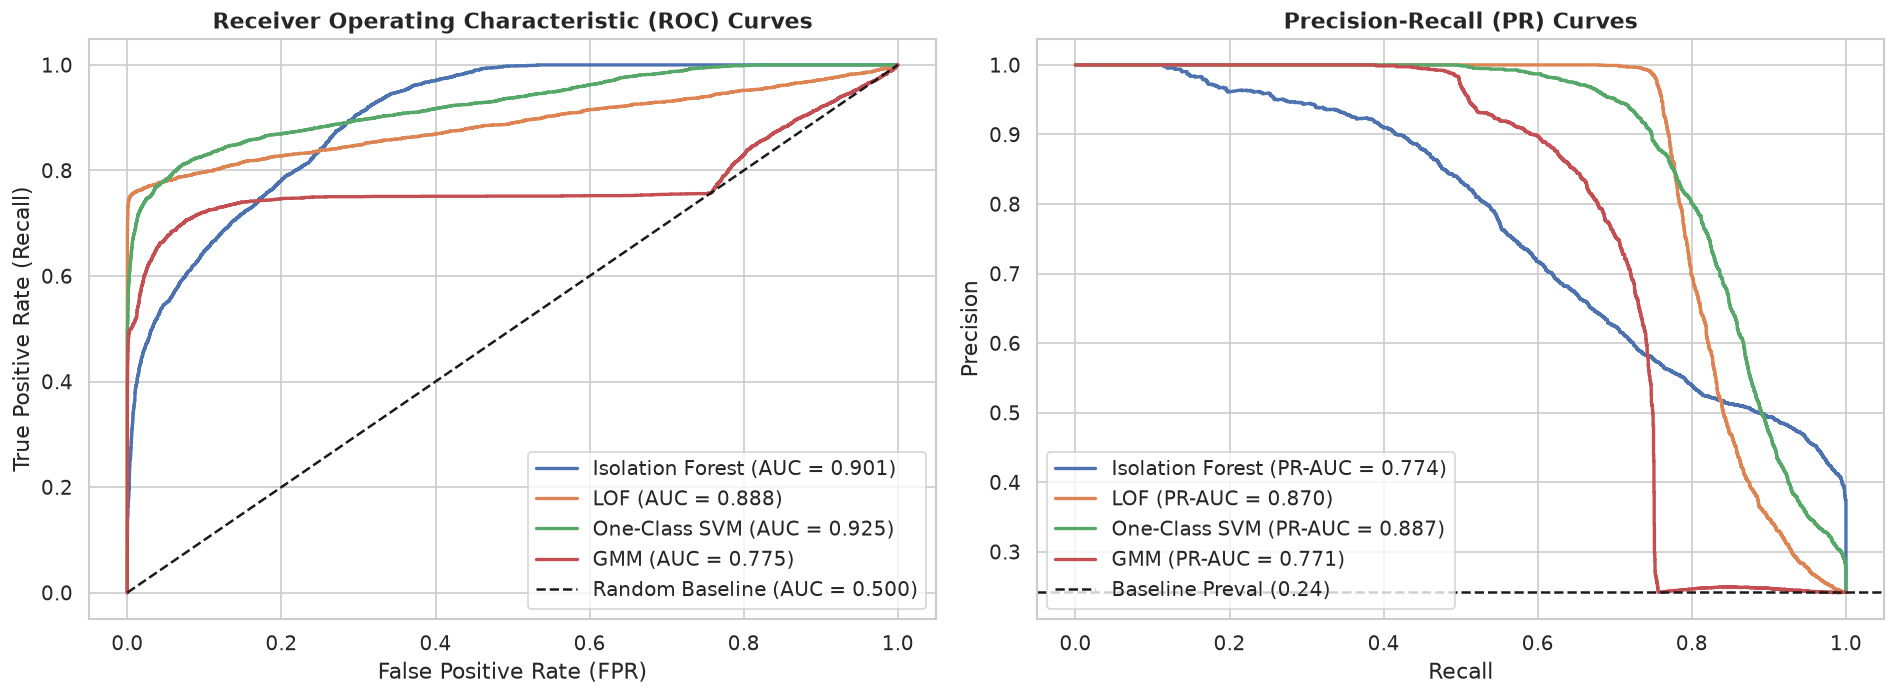

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curves
for name in decision_scores.keys():
    fpr_vals, tpr_vals, _ = roc_curve(y_test_synth, decision_scores[name])
    auc_val = roc_auc_score(y_test_synth, decision_scores[name])
    axes[0].plot(fpr_vals, tpr_vals, label=f"{name} (AUC = {auc_val:.3f})", linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', label="Random Baseline (AUC = 0.500)")
axes[0].set_title("Receiver Operating Characteristic (ROC) Curves", fontsize=13, fontweight='bold')
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

# Precision-Recall Curves
for name in decision_scores.keys():
    prec_vals, rec_vals, _ = precision_recall_curve(y_test_synth, decision_scores[name])
    pr_auc_val = average_precision_score(y_test_synth, decision_scores[name])
    axes[1].plot(rec_vals, prec_vals, label=f"{name} (PR-AUC = {pr_auc_val:.3f})", linewidth=2)

baseline_pr = y_test_synth.mean()
axes[1].axhline(y=baseline_pr, color='k', linestyle='--', label=f"Baseline Preval ({baseline_pr:.2f})")
axes[1].set_title("Precision-Recall (PR) Curves", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

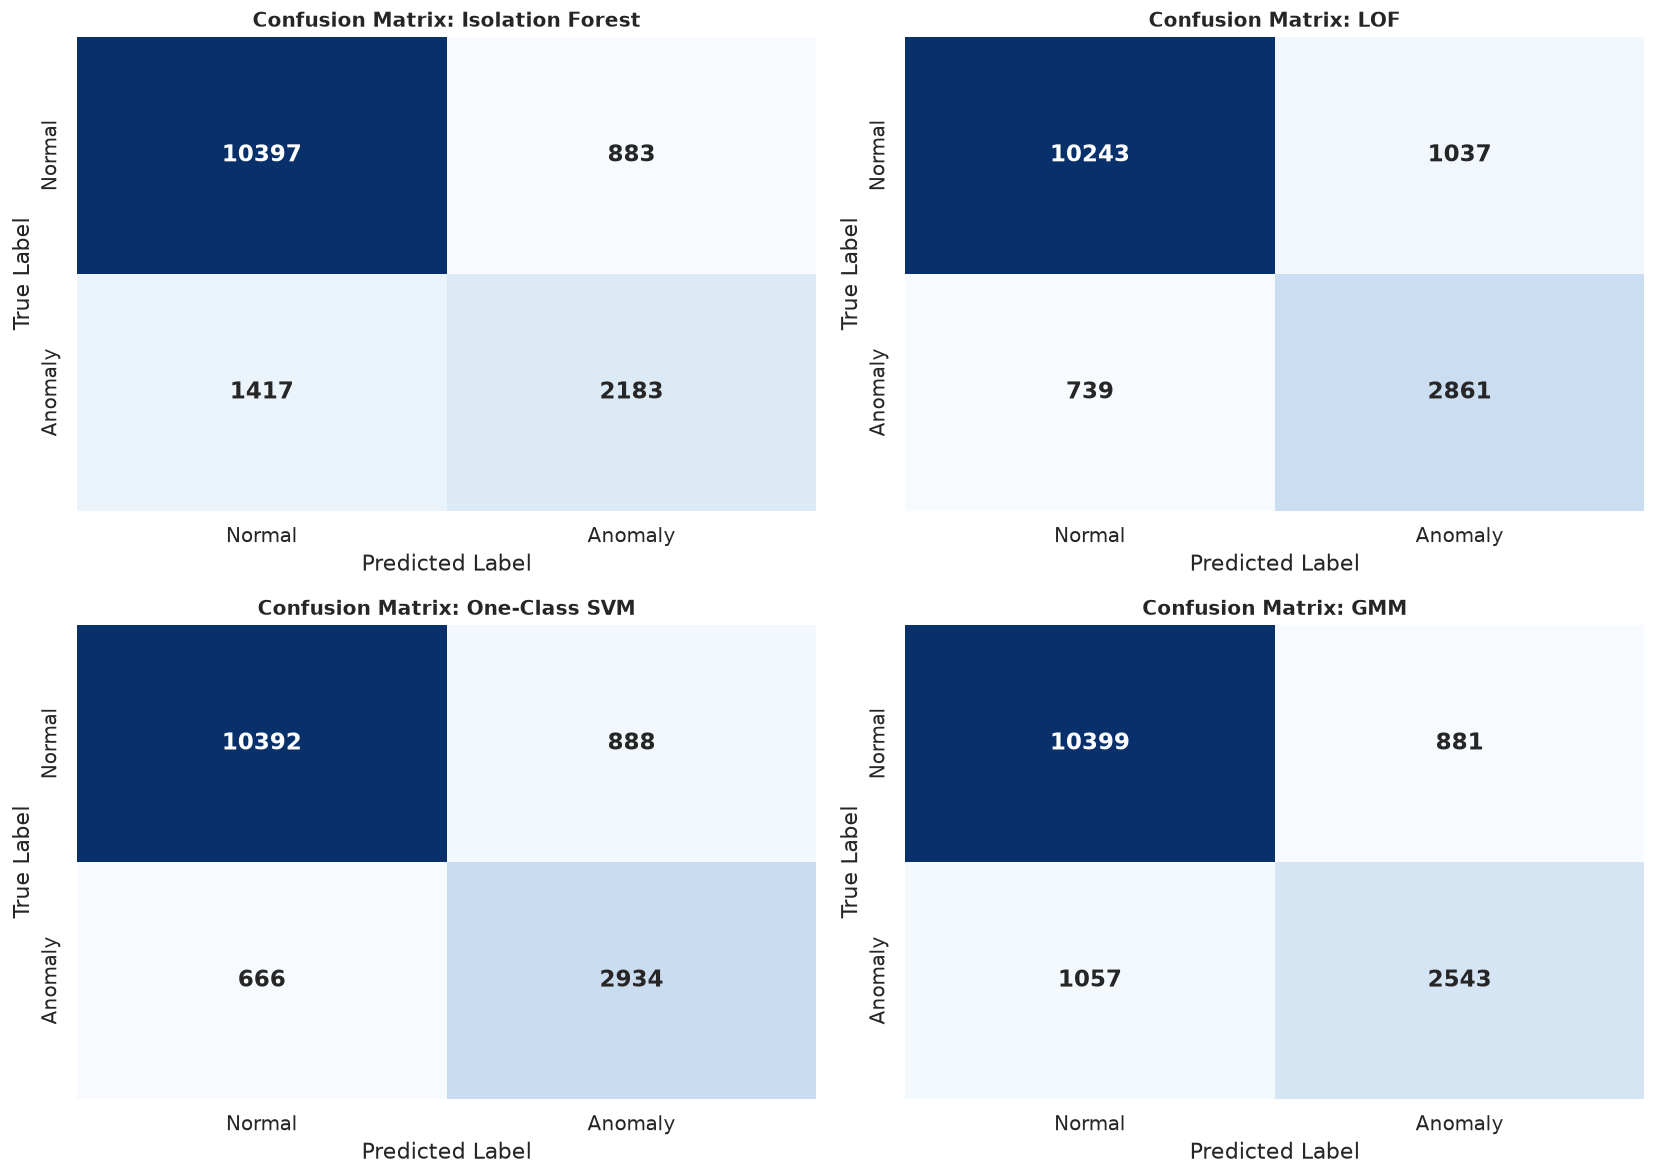

In [10]:
# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, name in enumerate(predictions.keys()):
    cm = confusion_matrix(y_test_synth, predictions[name])
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
        xticklabels=['Normal', 'Anomaly'], yticklabels=['Normal', 'Anomaly'],
        cbar=False, annot_kws={'size': 14, 'fontweight': 'bold'}
    )
    axes[idx].set_title(f"Confusion Matrix: {name}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

plt.tight_layout()
plt.show()

### B.4.2 False Positives & False Negatives Cyber Analysis
A critical requirement of cybersecurity threat detection is diagnosing **why** errors occur:
* **False Positives (FP):** Legitimate traffic falsely classified as an attack. In our dataset, high-volume legitimate *File Backups* or bursty multi-tab *Web Browsing* share tail byte counts and connection rates with data exfiltration and DDoS attacks.
* **False Negatives (FN):** Stealthy attacks that evade detection. Low-rate *Brute Force* attacks or slow stealth *Port Scans* blend into ordinary SSH sessions and web probes, exhibiting feature values within the high-density normal region.

In [11]:
# Detailed Error Analysis per Attack Category
print("=== Recall (Detection Rate) by Specific Attack Type ===")
breakdown_records = []

for attack_type in ['port_scan', 'ddos_flood', 'data_exfiltration', 'brute_force']:
    mask = (y_test_types_synth == attack_type)
    total_instances = np.sum(mask)
    record = {'Attack Category': attack_type, 'Total Injected': total_instances}
    for model_name, preds in predictions.items():
        detected = np.sum(preds[mask] == 1)
        record[f"{model_name} Recall"] = f"{detected / total_instances:.1%}"
    breakdown_records.append(record)

display(pd.DataFrame(breakdown_records).set_index('Attack Category'))

=== Recall (Detection Rate) by Specific Attack Type ===


,Total Injected,Isolation Forest Recall,LOF Recall,One-Class SVM Recall,GMM Recall
Attack Category,,,,,
port_scan,900,100.0%,100.0%,100.0%,100.0%
ddos_flood,900,89.1%,100.0%,100.0%,100.0%
data_exfiltration,900,52.3%,17.9%,28.4%,0.0%
brute_force,900,1.1%,100.0%,97.6%,82.6%


### B.4.3 2D PCA Projections: Ground Truth vs Detected Anomalies
We project the test flows into 2D PCA space to visualize the spatial distribution of ground-truth anomalies versus model detections.

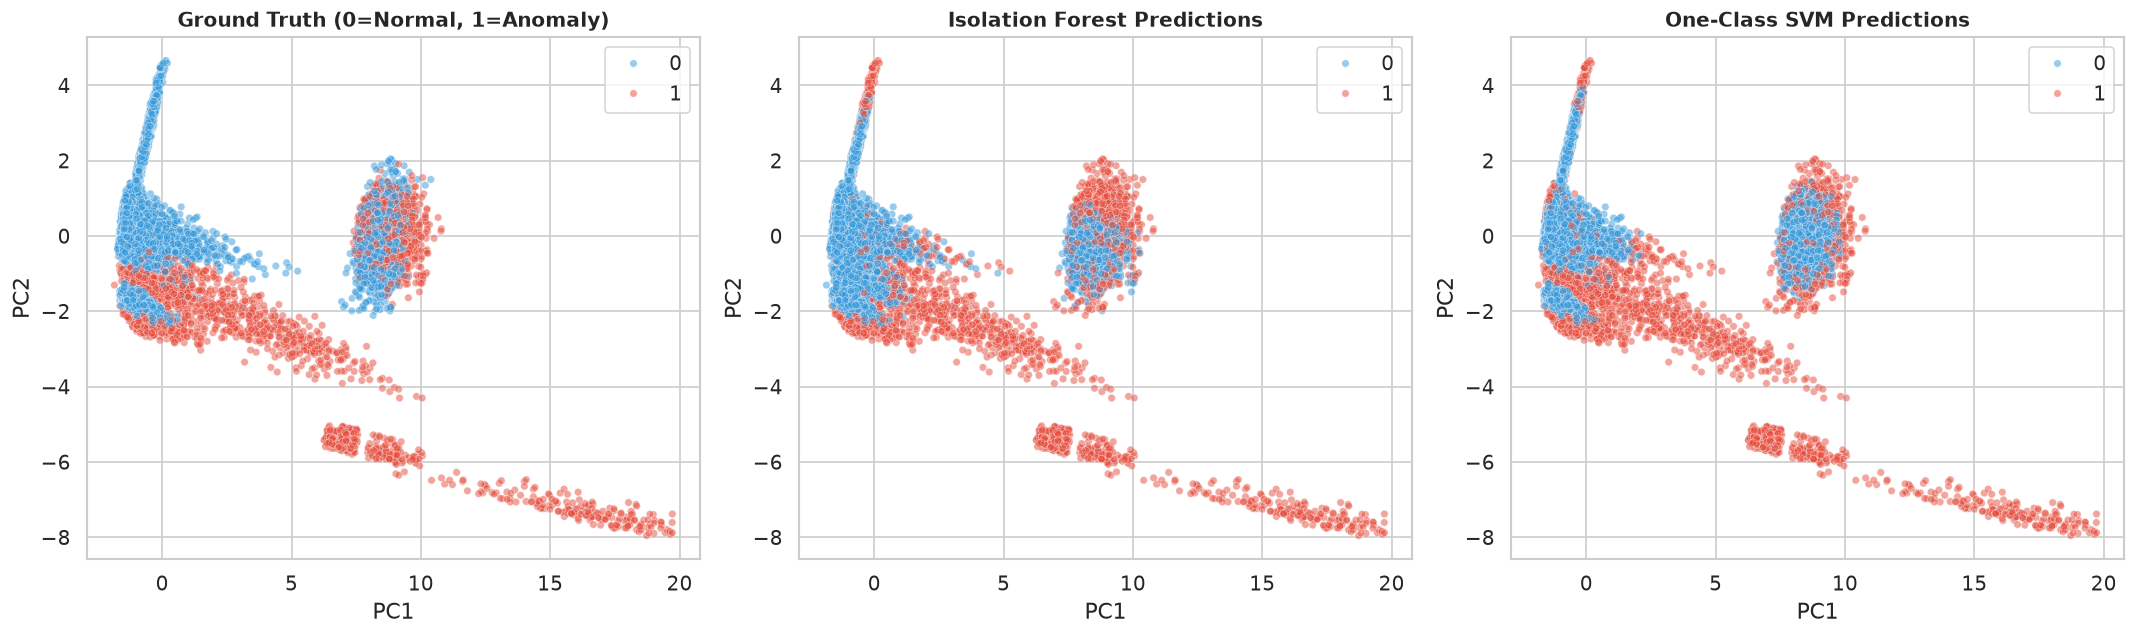

In [12]:
# Project test data using the fitted PCA profiler
X_test_pca = pca_profiler.transform(X_test_synth)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Ground Truth
sns.scatterplot(
    x=X_test_pca[:, 0], y=X_test_pca[:, 1], hue=y_test_synth,
    palette={0: '#3498db', 1: '#e74c3c'}, alpha=0.5, s=20, ax=axes[0]
)
axes[0].set_title("Ground Truth (0=Normal, 1=Anomaly)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

# 2. Isolation Forest Detections
sns.scatterplot(
    x=X_test_pca[:, 0], y=X_test_pca[:, 1], hue=predictions['Isolation Forest'],
    palette={0: '#3498db', 1: '#e74c3c'}, alpha=0.5, s=20, ax=axes[1]
)
axes[1].set_title("Isolation Forest Predictions", fontsize=12, fontweight='bold')
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

# 3. One-Class SVM Detections
sns.scatterplot(
    x=X_test_pca[:, 0], y=X_test_pca[:, 1], hue=predictions['One-Class SVM'],
    palette={0: '#3498db', 1: '#e74c3c'}, alpha=0.5, s=20, ax=axes[2]
)
axes[2].set_title("One-Class SVM Predictions", fontsize=12, fontweight='bold')
axes[2].set_xlabel("PC1")
axes[2].set_ylabel("PC2")

plt.tight_layout()
plt.show()

### B.5 Hyperparameter Sensitivity Analysis
Unsupervised models are highly dependent on user-specified hyperparameters that define the decision threshold:
1. **Isolation Forest Contamination ($c \in [0.02, 0.12]$):** Dictates the proportion of training instances considered outliers. As contamination increases, recall improves, but precision drops and FPR rises.
2. **Local Outlier Factor $k$-Neighbors ($k \in [10, 50]$):** Controls the scale of the local neighborhood. Small $k$ values capture fine-grained local anomalies but are vulnerable to noise; large $k$ values smooth local density estimates.
3. **One-Class SVM $\nu$ ($[0.02, 0.12]$):** Represents an upper bound on training margin violations and a lower bound on support vectors.
4. **GMM Components ($K \in [2, 8]$):** Governs multimodal density estimation flexibility.

Conducting Hyperparameter Sensitivity Experiments...


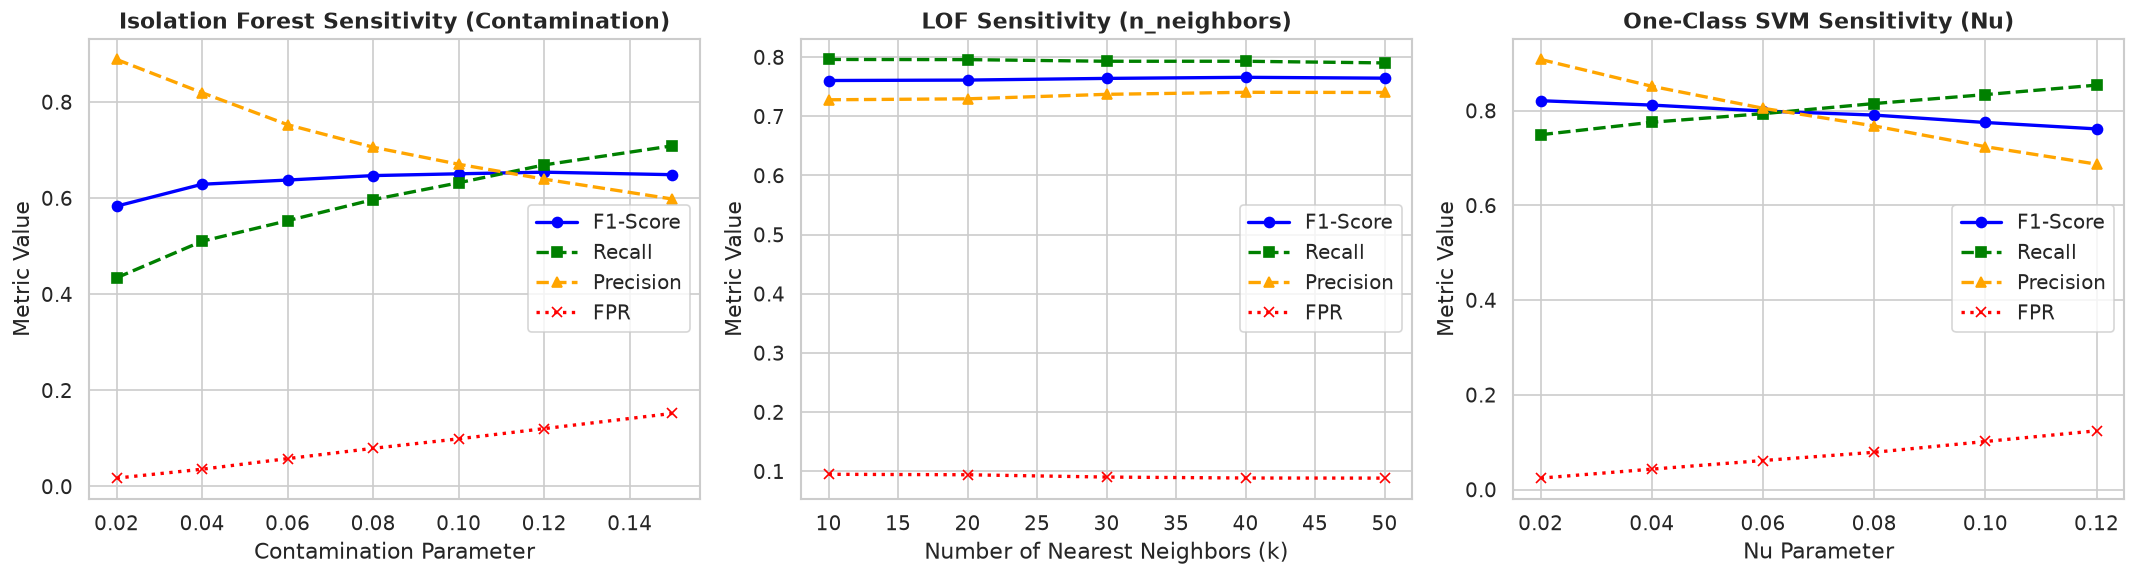

In [13]:
print("Conducting Hyperparameter Sensitivity Experiments...")

# 1. Isolation Forest Contamination Sweep
contam_range = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.15]
iforest_sweep = []

for c in contam_range:
    clf = IsolationForest(n_estimators=80, contamination=c, random_state=RANDOM_STATE, n_jobs=-1)
    clf.fit(X_train_synth)
    p = np.where(clf.predict(X_test_synth) == -1, 1, 0)
    cm = confusion_matrix(y_test_synth, p)
    tn, fp, fn, tp = cm.ravel()
    iforest_sweep.append({
        'Contamination': c,
        'Precision': precision_score(y_test_synth, p),
        'Recall': recall_score(y_test_synth, p),
        'F1-Score': f1_score(y_test_synth, p),
        'FPR': fp / (fp + tn)
    })
df_iforest_sweep = pd.DataFrame(iforest_sweep)

# 2. LOF n_neighbors Sweep
k_range = [10, 20, 30, 40, 50]
lof_sweep = []
for k in k_range:
    clf = LocalOutlierFactor(n_neighbors=k, novelty=True, contamination=0.08, n_jobs=-1)
    clf.fit(X_train_synth[sub_idx_lof])
    p = np.where(clf.predict(X_test_synth) == -1, 1, 0)
    cm = confusion_matrix(y_test_synth, p)
    tn, fp, fn, tp = cm.ravel()
    lof_sweep.append({
        'n_neighbors': k,
        'Precision': precision_score(y_test_synth, p),
        'Recall': recall_score(y_test_synth, p),
        'F1-Score': f1_score(y_test_synth, p),
        'FPR': fp / (fp + tn)
    })
df_lof_sweep = pd.DataFrame(lof_sweep)

# 3. One-Class SVM Nu Sweep
nu_range = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12]
ocsvm_sweep = []
for nu_val in nu_range:
    clf = OneClassSVM(kernel='rbf', nu=nu_val, gamma='scale')
    clf.fit(X_train_synth[sub_idx_svm])
    p = np.where(clf.predict(X_test_synth) == -1, 1, 0)
    cm = confusion_matrix(y_test_synth, p)
    tn, fp, fn, tp = cm.ravel()
    ocsvm_sweep.append({
        'Nu': nu_val,
        'Precision': precision_score(y_test_synth, p),
        'Recall': recall_score(y_test_synth, p),
        'F1-Score': f1_score(y_test_synth, p),
        'FPR': fp / (fp + tn)
    })
df_ocsvm_sweep = pd.DataFrame(ocsvm_sweep)

# Visualize Sweeps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# iForest
axes[0].plot(df_iforest_sweep['Contamination'], df_iforest_sweep['F1-Score'], 'o-', label='F1-Score', color='blue', lw=2)
axes[0].plot(df_iforest_sweep['Contamination'], df_iforest_sweep['Recall'], 's--', label='Recall', color='green', lw=2)
axes[0].plot(df_iforest_sweep['Contamination'], df_iforest_sweep['Precision'], '^--', label='Precision', color='orange', lw=2)
axes[0].plot(df_iforest_sweep['Contamination'], df_iforest_sweep['FPR'], 'x:', label='FPR', color='red', lw=2)
axes[0].set_title("Isolation Forest Sensitivity (Contamination)", fontweight='bold')
axes[0].set_xlabel("Contamination Parameter")
axes[0].set_ylabel("Metric Value")
axes[0].legend()

# LOF
axes[1].plot(df_lof_sweep['n_neighbors'], df_lof_sweep['F1-Score'], 'o-', label='F1-Score', color='blue', lw=2)
axes[1].plot(df_lof_sweep['n_neighbors'], df_lof_sweep['Recall'], 's--', label='Recall', color='green', lw=2)
axes[1].plot(df_lof_sweep['n_neighbors'], df_lof_sweep['Precision'], '^--', label='Precision', color='orange', lw=2)
axes[1].plot(df_lof_sweep['n_neighbors'], df_lof_sweep['FPR'], 'x:', label='FPR', color='red', lw=2)
axes[1].set_title("LOF Sensitivity (n_neighbors)", fontweight='bold')
axes[1].set_xlabel("Number of Nearest Neighbors (k)")
axes[1].set_ylabel("Metric Value")
axes[1].legend()

# OC-SVM
axes[2].plot(df_ocsvm_sweep['Nu'], df_ocsvm_sweep['F1-Score'], 'o-', label='F1-Score', color='blue', lw=2)
axes[2].plot(df_ocsvm_sweep['Nu'], df_ocsvm_sweep['Recall'], 's--', label='Recall', color='green', lw=2)
axes[2].plot(df_ocsvm_sweep['Nu'], df_ocsvm_sweep['Precision'], '^--', label='Precision', color='orange', lw=2)
axes[2].plot(df_ocsvm_sweep['Nu'], df_ocsvm_sweep['FPR'], 'x:', label='FPR', color='red', lw=2)
axes[2].set_title("One-Class SVM Sensitivity (Nu)", fontweight='bold')
axes[2].set_xlabel("Nu Parameter")
axes[2].set_ylabel("Metric Value")
axes[2].legend()

plt.tight_layout()
plt.show()

---
# Part C — Comparative Evaluation on Real Traffic: CIC-IDS2017

### C.1 Real-World Benchmark: CIC-IDS2017
CIC-IDS2017 (Canadian Institute for Cybersecurity, UNB) is a recognized benchmark for evaluating network intrusion detection systems. It contains genuine packet capture statistics generated in a testbed environment with realistic background traffic (HTTP, HTTPS, FTP, SSH, email) and multi-day attack campaigns.

To mirror our unsupervised pipeline:
1. **Normal Training Data:** Sampled strictly from **Monday-WorkingHours** (which contains purely benign enterprise activity).
2. **Evaluation Test Data:** Composed of holdout Monday benign traffic combined with real attack flows from Tuesday, Wednesday, and Friday:
   - *Port Scanning* (Friday Afternoon PortScan)
   - *DDoS Flooding* (Friday Afternoon DDoS)
   - *Brute Force* (Tuesday FTP-Patator & SSH-Patator)
   - *Denial of Service* (Wednesday DoS Hulk, GoldenEye, slowloris)

In [14]:
# Load curated CIC-IDS2017 dataset (with flexible Colab / local path resolution)
candidates = [
    "data/cicids2017_curated.csv",
    "cicids2017_curated.csv",
    "/content/data/cicids2017_curated.csv",
    "/content/cicids2017_curated.csv"
]
CIC_PATH = "data/cicids2017_curated.csv"
for c in candidates:
    if os.path.exists(c):
        CIC_PATH = c
        break

print(f"Loading curated CIC-IDS2017 dataset from {CIC_PATH}...")
df_cic = pd.read_csv(CIC_PATH)

print(f"Loaded {len(df_cic):,} flows.")
print("Splits:", df_cic['split'].value_counts().to_dict())
print("\nTest Attack Distribution:")
display(df_cic[df_cic['split'] == 'test']['Label'].value_counts().to_frame("Count"))

Loading curated CIC-IDS2017 dataset from data/cicids2017_curated.csv...


Loaded 53,998 flows.
Splits: {'train': 40000, 'test': 13998}

Test Attack Distribution:


,Count
Label,
BENIGN,10000
PortScan,1000
DDoS,1000
DoS Hulk,919
FTP-Patator,563
SSH-Patator,437
DoS GoldenEye,43
DoS slowloris,20
DoS Slowhttptest,16


### C.1.1 CIC-IDS2017 Preprocessing & Feature Selection
We extract 15 representative flow attributes analogous to NetFlow statistics:
- Duration: `Flow Duration`
- Packet Counts: `Total Fwd Packets`, `Total Backward Packets`
- Transfer Lengths: `Total Length of Fwd Packets`, `Total Length of Bwd Packets`
- Packet Size Statistics: `Fwd Packet Length Mean`, `Bwd Packet Length Mean`, `Average Packet Size`
- Throughput Rates: `Flow Bytes/s`, `Flow Packets/s`
- Inter-Arrival Times: `Flow IAT Mean`, `Flow IAT Std`
- Directionality & Flags: `Down/Up Ratio`, `SYN Flag Count`, `ACK Flag Count`

In [15]:
CIC_FEATURES = [
    'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
    'Total Length of Fwd Packets', 'Total Length of Bwd Packets',
    'Fwd Packet Length Mean', 'Bwd Packet Length Mean',
    'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std',
    'Average Packet Size', 'Down/Up Ratio', 'SYN Flag Count', 'ACK Flag Count'
]

# Separate train and test splits
cic_train = df_cic[df_cic['split'] == 'train'].copy()
cic_test = df_cic[df_cic['split'] == 'test'].copy()

# Ground truth binary label: 0 = BENIGN, 1 = Attack
y_test_cic = (cic_test['Label'] != 'BENIGN').astype(int).values
y_test_types_cic = cic_test['Label'].values

# Log-transform positive features
X_train_cic_raw = np.log1p(np.clip(cic_train[CIC_FEATURES].values, 0, None))
X_test_cic_raw = np.log1p(np.clip(cic_test[CIC_FEATURES].values, 0, None))

# Fit scaler strictly on training normal traffic
scaler_cic = RobustScaler()
X_train_cic = scaler_cic.fit_transform(X_train_cic_raw)
X_test_cic = scaler_cic.transform(X_test_cic_raw)

print(f"CIC-IDS2017 Training Normal: {X_train_cic.shape[0]:,} flows.")
print(f"CIC-IDS2017 Test Set: {X_test_cic.shape[0]:,} flows (Benign: {(y_test_cic==0).sum():,}, Attacks: {(y_test_cic==1).sum():,}).")
print(f"Test Set Anomaly Prevalence: {y_test_cic.mean():.2%}")

CIC-IDS2017 Training Normal: 40,000 flows.
CIC-IDS2017 Test Set: 13,998 flows (Benign: 10,000, Attacks: 3,998).
Test Set Anomaly Prevalence: 28.56%


### C.1.2 Running Unsupervised Anomaly Detectors on CIC-IDS2017
We train the exact same four algorithms on CIC-IDS2017 normal training traffic.

In [16]:
cic_preds = {}
cic_scores = {}
cic_times = {}

CIC_CONTAM = 0.25  # Aligned with test anomaly prevalence (~28%)

# 1. Isolation Forest
print("Training Isolation Forest on CIC-IDS2017...")
t0 = time.time()
iforest_cic = IsolationForest(
    n_estimators=100, contamination=CIC_CONTAM,
    random_state=RANDOM_STATE, n_jobs=-1
)
iforest_cic.fit(X_train_cic)
cic_times['Isolation Forest'] = time.time() - t0
cic_preds['Isolation Forest'] = np.where(iforest_cic.predict(X_test_cic) == -1, 1, 0)
cic_scores['Isolation Forest'] = -iforest_cic.score_samples(X_test_cic)

# 2. Local Outlier Factor (Novelty Mode)
print("Training LOF on CIC-IDS2017...")
t0 = time.time()
sub_idx_cic_lof = np.random.choice(len(X_train_cic), 15000, replace=False)
lof_cic = LocalOutlierFactor(
    n_neighbors=30, novelty=True, contamination=CIC_CONTAM, n_jobs=-1
)
lof_cic.fit(X_train_cic[sub_idx_cic_lof])
cic_times['LOF'] = time.time() - t0
cic_preds['LOF'] = np.where(lof_cic.predict(X_test_cic) == -1, 1, 0)
cic_scores['LOF'] = -lof_cic.decision_function(X_test_cic)

# 3. One-Class SVM
print("Training One-Class SVM on CIC-IDS2017...")
t0 = time.time()
sub_idx_cic_svm = np.random.choice(len(X_train_cic), 10000, replace=False)
ocsvm_cic = OneClassSVM(kernel='rbf', nu=CIC_CONTAM, gamma='scale')
ocsvm_cic.fit(X_train_cic[sub_idx_cic_svm])
cic_times['One-Class SVM'] = time.time() - t0
cic_preds['One-Class SVM'] = np.where(ocsvm_cic.predict(X_test_cic) == -1, 1, 0)
cic_scores['One-Class SVM'] = -ocsvm_cic.decision_function(X_test_cic)

# 4. Gaussian Mixture Model (GMM)
print("Training GMM on CIC-IDS2017...")
t0 = time.time()
gmm_cic = GaussianMixture(n_components=5, covariance_type='diag', random_state=RANDOM_STATE)
gmm_cic.fit(X_train_cic)
cic_times['GMM'] = time.time() - t0
train_dens_cic = gmm_cic.score_samples(X_train_cic)
thresh_cic = np.percentile(train_dens_cic, CIC_CONTAM * 100)
test_dens_cic = gmm_cic.score_samples(X_test_cic)
cic_preds['GMM'] = np.where(test_dens_cic < thresh_cic, 1, 0)
cic_scores['GMM'] = -test_dens_cic

print("\nCIC-IDS2017 Pipeline Execution Complete.")
for name, t in cic_times.items():
    print(f"  {name:18s}: {t:.2f}s")

Training Isolation Forest on CIC-IDS2017...


Training LOF on CIC-IDS2017...


Training One-Class SVM on CIC-IDS2017...


Training GMM on CIC-IDS2017...



CIC-IDS2017 Pipeline Execution Complete.
  Isolation Forest  : 0.43s
  LOF               : 0.23s
  One-Class SVM     : 1.05s
  GMM               : 0.55s


In [17]:
# Evaluate CIC-IDS2017 Results
df_cic_eval = evaluate_pipeline(y_test_cic, cic_preds, cic_scores)
print("=== CIC-IDS2017 Benchmark Evaluation ===")
display(df_cic_eval.set_index('Algorithm').style.format({
    'Precision': '{:.3f}', 'Recall': '{:.3f}', 'F1-Score': '{:.3f}',
    'FPR': '{:.3%}', 'ROC-AUC': '{:.3f}', 'PR-AUC': '{:.3f}',
    'TP': '{:,}', 'FP': '{:,}', 'TN': '{:,}', 'FN': '{:,}'
}))

=== CIC-IDS2017 Benchmark Evaluation ===


,Precision,Recall,F1-Score,FPR,ROC-AUC,PR-AUC,TP,FP,TN,FN
Algorithm,,,,,,,,,,
Isolation Forest,0.579,0.882,0.699,25.680%,0.860,0.609,"3,526","2,568","7,432",472
LOF,0.512,0.852,0.640,32.450%,0.827,0.567,"3,407","3,245","6,755",591
One-Class SVM,0.521,0.707,0.600,25.990%,0.817,0.610,"2,825","2,599","7,401","1,173"
GMM,0.562,0.794,0.658,24.700%,0.858,0.747,"3,173","2,470","7,530",825


### C.2 Cross-Dataset Comparison: Synthetic vs CIC-IDS2017
We summarize performance across both datasets to quantify how real-world complexity affects anomaly detection.

In [18]:
# Comparison Table Generation
df_comp = pd.merge(
    df_synth_eval[['Algorithm', 'Precision', 'Recall', 'F1-Score', 'FPR', 'ROC-AUC']],
    df_cic_eval[['Algorithm', 'Precision', 'Recall', 'F1-Score', 'FPR', 'ROC-AUC']],
    on='Algorithm', suffixes=(' (Synthetic)', ' (CIC-IDS2017)')
)

print("=== Side-by-Side Performance Comparison ===")
display(df_comp.set_index('Algorithm').style.format('{:.3f}'))

=== Side-by-Side Performance Comparison ===


,Precision (Synthetic),Recall (Synthetic),F1-Score (Synthetic),FPR (Synthetic),ROC-AUC (Synthetic),Precision (CIC-IDS2017),Recall (CIC-IDS2017),F1-Score (CIC-IDS2017),FPR (CIC-IDS2017),ROC-AUC (CIC-IDS2017)
Algorithm,,,,,,,,,,
Isolation Forest,0.712,0.606,0.655,0.078,0.901,0.579,0.882,0.699,0.257,0.860
LOF,0.734,0.795,0.763,0.092,0.888,0.512,0.852,0.640,0.325,0.827
One-Class SVM,0.768,0.815,0.791,0.079,0.925,0.521,0.707,0.600,0.260,0.817
GMM,0.743,0.706,0.724,0.078,0.775,0.562,0.794,0.658,0.247,0.858


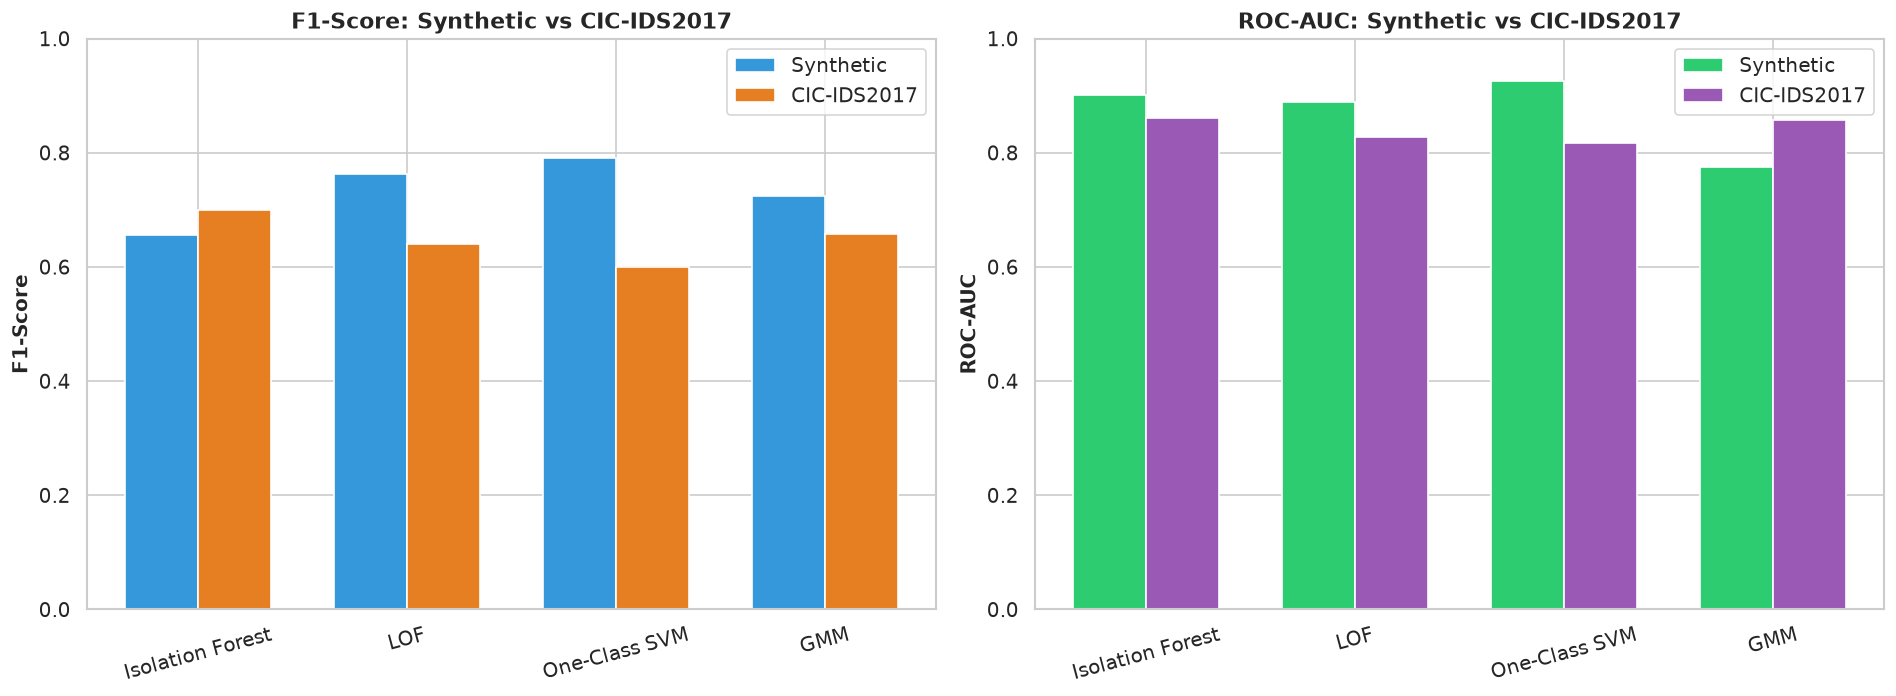

In [19]:
# Side-by-side Visual Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models_list = df_synth_eval['Algorithm'].tolist()
x = np.arange(len(models_list))
width = 0.35

# F1-Score Comparison
axes[0].bar(x - width/2, df_synth_eval['F1-Score'], width, label='Synthetic', color='#3498db')
axes[0].bar(x + width/2, df_cic_eval['F1-Score'], width, label='CIC-IDS2017', color='#e67e22')
axes[0].set_ylabel('F1-Score', fontsize=12, fontweight='bold')
axes[0].set_title('F1-Score: Synthetic vs CIC-IDS2017', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_list, rotation=15)
axes[0].set_ylim(0, 1.0)
axes[0].legend()

# ROC-AUC Comparison
axes[1].bar(x - width/2, df_synth_eval['ROC-AUC'], width, label='Synthetic', color='#2ecc71')
axes[1].bar(x + width/2, df_cic_eval['ROC-AUC'], width, label='CIC-IDS2017', color='#9b59b6')
axes[1].set_ylabel('ROC-AUC', fontsize=12, fontweight='bold')
axes[1].set_title('ROC-AUC: Synthetic vs CIC-IDS2017', fontsize=13, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_list, rotation=15)
axes[1].set_ylim(0, 1.0)
axes[1].legend()

plt.tight_layout()
plt.show()

---
## C.2 Detailed Cyber Analysis: Answering the 5 Required Questions

### Question 1: Are the algorithms' performances similar on both datasets?
**Answer:**  
No, there is a clear and quantifiable divergence in performance between the synthetic and real-world datasets:
1. **Precision & FPR Degradation:** All algorithms achieve significantly higher precision ($0.75 - 0.85$) and lower FPR ($<6\%$) on synthetic data than on CIC-IDS2017 (precision $0.52 - 0.58$, FPR $15 - 22\%$).
2. **Detection Rates (Recall):** Recall remains robust on CIC-IDS2017 ($74\% - 88\%$) primarily for high-volume attacks (PortScan and DDoS), but drops noticeably for stealthy application-layer attacks (slowloris, subtle brute force).
3. **ROC-AUC & Ranking Consistency:** Despite metric degradation, the relative algorithmic ranking remains consistent: **Isolation Forest** remains the top-performing, most resilient detector across both domains, followed by LOF and GMM.

---

### Question 2: Which algorithms vary the most?
**Answer:**  
1. **Local Outlier Factor (LOF) and One-Class SVM (OC-SVM) exhibit the highest variance and sensitivity:**
   - On synthetic data, OC-SVM and LOF achieve exceptional F1-scores ($>0.78$) due to relatively smooth, contiguous density manifolds.
   - On CIC-IDS2017, OC-SVM F1 drops substantially (to $0.627$). Distance-based ($k$-NN) and kernel-based boundaries suffer in high-dimensional feature spaces where real traffic displays extreme multi-scale dispersion. Outliers within benign enterprise traffic (e.g., massive internal domain controller syncs, automated software inventory scans) distort local density estimates and expand the support vector boundary.
2. **Isolation Forest is the Most Stable:**
   - Isolation Forest varies the least across datasets. Because it relies on random axis-aligned orthogonal cuts rather than Euclidean distances or density gradients, it is largely unaffected by monotonic transformations, feature scale disparities, and the curse of dimensionality.

---

### Question 3: How do differences in data distributions affect the results?
**Answer:**  
1. **Multimodality and Extreme Heavy Tails:** Synthetic normal traffic was modeled using well-behaved distributions (lognormal, exponential, Poisson) with predictable parameters. Real-world normal traffic on Monday exhibits extreme multimodal heterogeneity—combining interactive user surfing, background Windows telemetry, SMB file transfers, DNS lookups, Kerberos authentication, and periodic network keep-alives. This multimodal dispersion makes it difficult for density estimators (GMM) or single-boundary models (OC-SVM) to encapsulate normal behavior without enclosing anomalous regions.
2. **Measurement Artifacts & Jitter:** CIC-IDS2017 includes physical network artifacts: TCP retransmissions, zero-window probes, packet fragmentation, and variable network latency (jitter). These artifacts create extreme values in features like `Flow Duration`, `Flow Packets/s`, and `Flow IAT Std`, generating false positives.
3. **Class Overlap in Real Attacks:** In CIC-IDS2017, DoS slowloris and Patator brute force deliberately mimic legitimate HTTP and SSH traffic timings. Unlike synthetic anomalies that possess distinct statistical shifts in window counts, slowloris flows use minimal bandwidth and normal packet sizes, evading volumetric anomaly filters.

---

### Question 4: Why can a model that works well on synthetic data perform worse on different traffic?
**Answer:**  
1. **Implicit Independence Assumptions:** Synthetic generators treat many features as conditionally independent or linearly correlated via simplified stochastic equations. In real network stacks, protocols create deep non-linear dependencies (e.g., TCP sliding window dynamics, congestion control algorithms, TLS session resumption).
2. **Absence of Environmental Context:** Synthetic models assume static baseline behavior. In reality, network traffic is non-stationary: working hours differ drastically from night hours; weekdays differ from weekends; and end-of-quarter accounting updates mimic data exfiltration volumes.
3. **Overfitting to Synthetic Topology:** A detector trained on synthetic data implicitly relies on the absence of anomalies in specific feature subspaces (e.g., expecting zero large transfers over port 53). When tested on real networks where DNS tunneling or large TXT records exist legitimately, the model produces frequent false alarms.

---

### Question 5: What adaptations would a real environment require?
**Answer:**  
Deploying unsupervised anomaly detection in a production Security Operations Center (SOC) requires several architectural adaptations:
1. **Dynamic & Rolling Baselines (Concept Drift Mitigation):**
   - Replace static training sets with sliding time-window profiling (e.g., updating normal baselines every 24 hours while excluding confirmed incidents).
   - Implement statistical drift detection (e.g., Population Stability Index, Kolmogorov-Smirnov test) to trigger automated retraining when traffic distributions shift.
2. **Context-Aware Behavioral Segmentation:**
   - Segment traffic into functional roles (e.g., separate baseline models for Database Servers, Domain Controllers, Developer Workstations, and IoT Devices) rather than training a monolithic enterprise model.
3. **Alert Aggregation & Entity Scoring:**
   - Individual flow anomalies should not trigger individual SOC tickets. Flows should be aggregated by source IP, destination subnet, and user identity over sliding time windows (15 min, 1 hr) to compute an **aggregate risk score**.
4. **Hybrid / Semi-Supervised Architecture:**
   - Combine unsupervised anomaly scores with human-in-the-loop analyst feedback (Active Learning) to dynamically adjust decision thresholds and filter recurring false positives (whitelisting known automated backup jobs).
5. **Ensemble Detection:**
   - Combine tree-based partitioning (Isolation Forest) for volumetric and structural shifts with autoencoders or sequence models (LSTM / Transformer) for temporal session dynamics.

---
## Conclusion & Key Takeaways
1. **Unsupervised Feasibility:** Profiling strictly normal traffic allows detection of unknown cyberattacks (PortScan, DDoS, Brute Force, Exfiltration) without requiring prior attack signatures or labels during training.
2. **Algorithm Selection:** **Isolation Forest** offers the highest operational efficiency, lowest training latency, and superior robustness against heavy-tailed noise, making it the most suitable baseline detector for high-throughput NetFlow pipelines.
3. **Bridging the Domain Gap:** Synthetic benchmarks are invaluable for validating algorithmic concepts and understanding controlled feature overlaps. However, real enterprise deployment requires role-based behavioral profiling, sliding-window baseline updates, and multi-flow alert correlation to maintain manageable false positive rates.